In [46]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

In [47]:
class QuadState(TypedDict):
    a: int
    b: int
    c: int
    equation: str
    discriminant: float
    result: str

In [48]:
def show_equation(state: QuadState):
    equation = f"{state['a']}x2{state['b']}x{state['c']}"
    return {'equation': equation}

def calcualte_discriminant(state: QuadState):
    discriminant = state['b']**2 - (4*state['a']*state['c'])
    return {'discriminant': discriminant}

def real_roots(state: QuadState):
    root1 = (-state['b']+ state['discriminant']**0.5)/(2*state['a'])
    root2 = (-state['b']- state['discriminant']**0.5)/(2*state['a'])

    result = f"The roots are {root1} and {root2}"

    return {'result':result}

def repeated_roots(state: QuadState):
    root = (-state['b'])/(2*state['a'])
    result = f"Only repeating root is {root}"

    return {'result':result}

def no_real_roots(state: QuadState):
    result = f"No real roots"
    return {'result':result}

def check_condition(state: QuadState) -> Literal['real_roots','repeated_roots','no_real_roots']:
    if state['discriminant'] > 0:
        return 'real_roots'
    elif state['discriminant'] == 0:
        return 'repeated_roots'
    else:
        return 'no_real_roots'

In [49]:
graph = StateGraph(QuadState)

graph.add_node('show_equation', show_equation)
graph.add_node('calcualte_discriminant', calcualte_discriminant)
graph.add_node('real_roots', real_roots)
graph.add_node('repeated_roots', repeated_roots)
graph.add_node('no_real_roots', no_real_roots)

graph.add_edge(START, 'show_equation')
graph.add_edge('show_equation', 'calcualte_discriminant')
graph.add_conditional_edges('calcualte_discriminant',check_condition)
graph.add_edge('real_roots', END)
graph.add_edge('repeated_roots', END)
graph.add_edge('no_real_roots', END)

workflow = graph.compile()

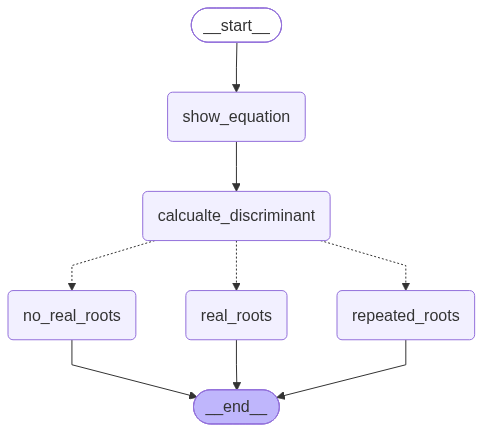

In [50]:
workflow

In [54]:
initial_state = {
    'a': 4,
    'b': 7,
    'c':4
}
workflow.invoke(initial_state)

{'a': 4,
 'b': 7,
 'c': 4,
 'equation': '4x27x4',
 'discriminant': -15,
 'result': 'No real roots'}